# 02 · Modelagem — prevendo o churn e medindo o retorno em dinheiro

**Objetivo:** dar a cada cliente uma probabilidade de cancelamento e decidir **quem deve receber uma oferta de retenção** de forma que a campanha dê o maior lucro possível.

**Como evitei vazamento de dados (data leakage)**
- 20% dos clientes ficam separados como **teste** e só são usados uma vez, no final.
- Toda transformação (novas variáveis, one-hot, padronização) fica dentro de um `sklearn.Pipeline`, ajustado apenas nos dados de cada fold de treino.
- O **limiar de decisão** é escolhido com previsões *out-of-fold* do treino — nunca olhando o teste.

O código completo está em `src/churn/train.py`. Aqui eu executo e interpreto os resultados.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
from IPython.display import Image, display

from churn.data import clean, load_raw
from churn.features import add_features
from churn import plots

pd.set_option("display.max_columns", 30)
FIG = RAIZ / "reports" / "figures"
import json
from churn.train import main

## 1. Treino e comparação dos modelos

In [2]:
metricas = main()

Treino: 5,634 clientes | Teste: 1,409 clientes | churn 26.5%


  Baseline (sem modelo)    ROC-AUC 0.500 ± 0.000 | PR-AUC 0.265 ± 0.000


  Regressão Logística      ROC-AUC 0.847 ± 0.012 | PR-AUC 0.660 ± 0.015


  Random Forest            ROC-AUC 0.844 ± 0.010 | PR-AUC 0.657 ± 0.024


  XGBoost                  ROC-AUC 0.847 ± 0.010 | PR-AUC 0.664 ± 0.022

Melhor modelo na validação cruzada: XGBoost


Limiar que maximiza o lucro (out-of-fold, treino): 0.20



TESTE (XGBoost, limiar 0.20): ROC-AUC 0.846 | PR-AUC 0.666 | recall 84.5% | precisão 47.8%
Lucro: modelo US$ 52,111 | limiar 0,5 US$ 39,814 | todos US$ 27,524 | aleatório US$ 13,319
Concluído em 25s


In [3]:
cv = pd.DataFrame(metricas["validacao_cruzada"]).set_index("modelo")
cv.columns = ["ROC-AUC (média)", "ROC-AUC (desvio)", "PR-AUC (média)", "PR-AUC (desvio)"]
cv.round(3)

,ROC-AUC (média),ROC-AUC (desvio),PR-AUC (média),PR-AUC (desvio)
modelo,,,,
XGBoost,0.847,0.010,0.664,0.022
Regressão Logística,0.847,0.012,0.660,0.015
Random Forest,0.844,0.010,0.657,0.024
Baseline (sem modelo),0.500,0.000,0.265,0.000


**Leitura honesta dos resultados:** Regressão Logística, Random Forest e XGBoost ficam praticamente empatados (diferenças menores que o desvio padrão entre folds). O XGBoost foi escolhido por ter a maior PR-AUC média, mas **a Regressão Logística é uma alternativa igualmente válida** e mais fácil de explicar. Em um projeto real, eu levaria essa troca (desempenho x interpretabilidade) para a área de negócio decidir.

Todos superam com folga o baseline (ROC-AUC 0,50 / PR-AUC 0,27).

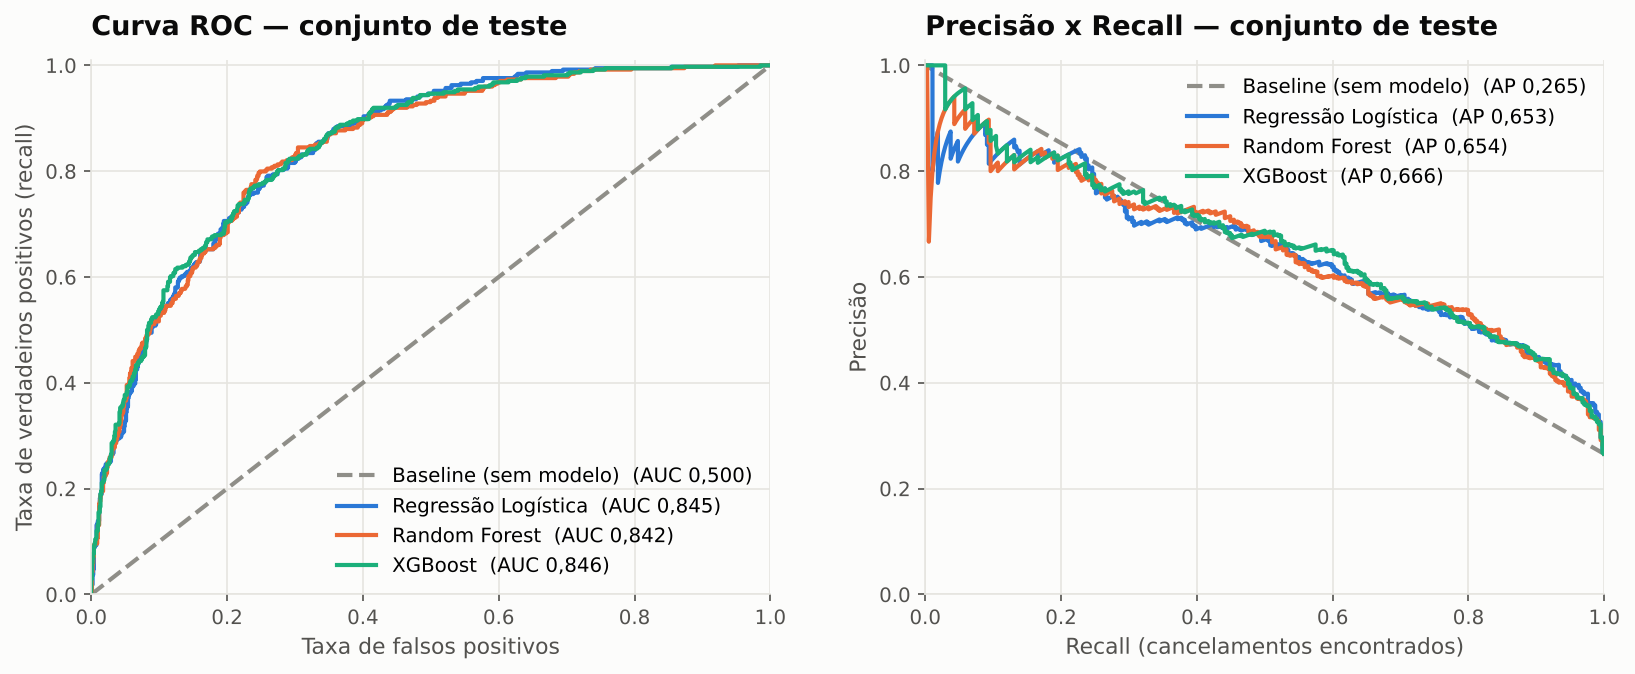

In [4]:
display(Image(FIG / "05_curvas_roc_pr.png"))

## 2. De probabilidade para decisão: escolhendo o limiar pelo lucro

O padrão de mercado é classificar como "vai cancelar" quem tem probabilidade ≥ 0,50. Mas esse número é arbitrário. Usei premissas de negócio explícitas (em `src/churn/config.py`, fáceis de ajustar):

| Premissa | Valor |
|---|---|
| Custo de abordar um cliente com oferta | US$ 50 |
| Chance de a oferta reter quem iria sair | 30% |
| Receita preservada ao reter um cliente | 12 mensalidades |

**Lucro = (clientes retidos × 12 mensalidades) − (clientes abordados × US$ 50)**

Como errar um cancelamento custa muito mais do que abordar alguém que ficaria, o limiar ótimo é bem menor que 0,50.

Limiar escolhido (out-of-fold no treino): 0.20


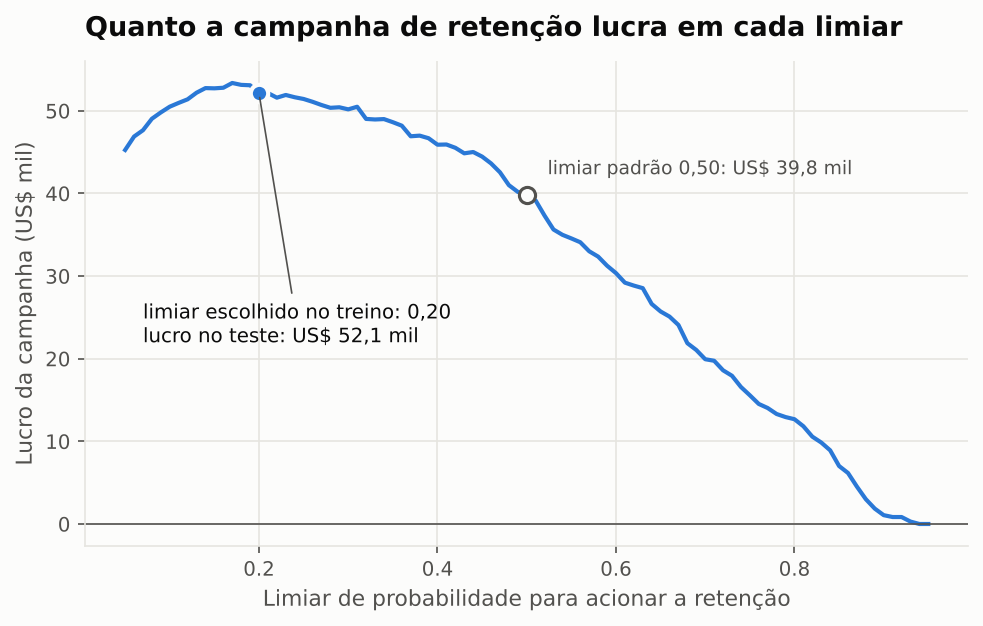

In [5]:
print(f"Limiar escolhido (out-of-fold no treino): {metricas['limiar_decisao']:.2f}")
display(Image(FIG / "07_curva_lucro.png"))

In [6]:
neg = metricas["negocio_teste"]
comparacao = pd.Series({
    "Não fazer nada": neg["lucro_nao_fazer_nada"],
    "Abordar 100% da base": neg["lucro_abordar_todos"],
    "Abordar ao acaso (mesmo volume do modelo)": neg["lucro_abordagem_aleatoria_mesmo_volume"],
    "Modelo com limiar padrão 0,50": neg["lucro_modelo_limiar_0_5"],
    "Modelo com limiar otimizado": neg["lucro_modelo_limiar_otimo"],
}, name="Lucro no teste (US$)")
comparacao.round(0).to_frame()

,Lucro no teste (US$)
Não fazer nada,0.0
Abordar 100% da base,27524.0
Abordar ao acaso (mesmo volume do modelo),13319.0
"Modelo com limiar padrão 0,50",39814.0
Modelo com limiar otimizado,52111.0


No conjunto de teste (1.409 clientes):
- O modelo com limiar otimizado gera **~US$ 52 mil** de lucro, **31% a mais** que o mesmo modelo com o limiar padrão 0,50 e quase **4x mais** que abordar o mesmo número de clientes ao acaso.
- O ponto ótimo exato no teste fica um pouco antes de 0,20 (a curva é plana nessa região), o que mostra que o limiar escolhido no treino generalizou bem.

## 3. Qualidade das decisões

ROC-AUC: 0.846 | PR-AUC: 0.666
Recall: 84.5% dos cancelamentos foram identificados
Precisão: 47.8% dos abordados realmente iriam cancelar
Clientes abordados: 661 (47% da base)


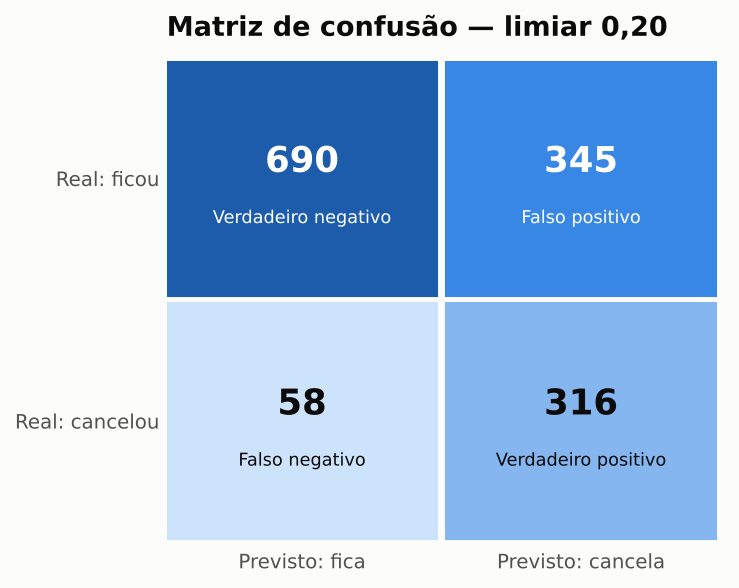

In [7]:
t = metricas["teste"]
print(f"ROC-AUC: {t['roc_auc']:.3f} | PR-AUC: {t['pr_auc']:.3f}")
print(f"Recall: {t['recall']:.1%} dos cancelamentos foram identificados")
print(f"Precisão: {t['precisao']:.1%} dos abordados realmente iriam cancelar")
print(f"Clientes abordados: {t['clientes_abordados']} ({t['pct_base_abordada']:.0%} da base)")
display(Image(FIG / "06_matriz_confusao.png"))

O modelo encontra **84,5% dos clientes que iriam cancelar** abordando 47% da base. O custo disso são os falsos positivos (clientes que ficariam de qualquer jeito e recebem a oferta) — um custo que a curva de lucro já mostrou valer a pena.

## 4. O que o modelo aprendeu

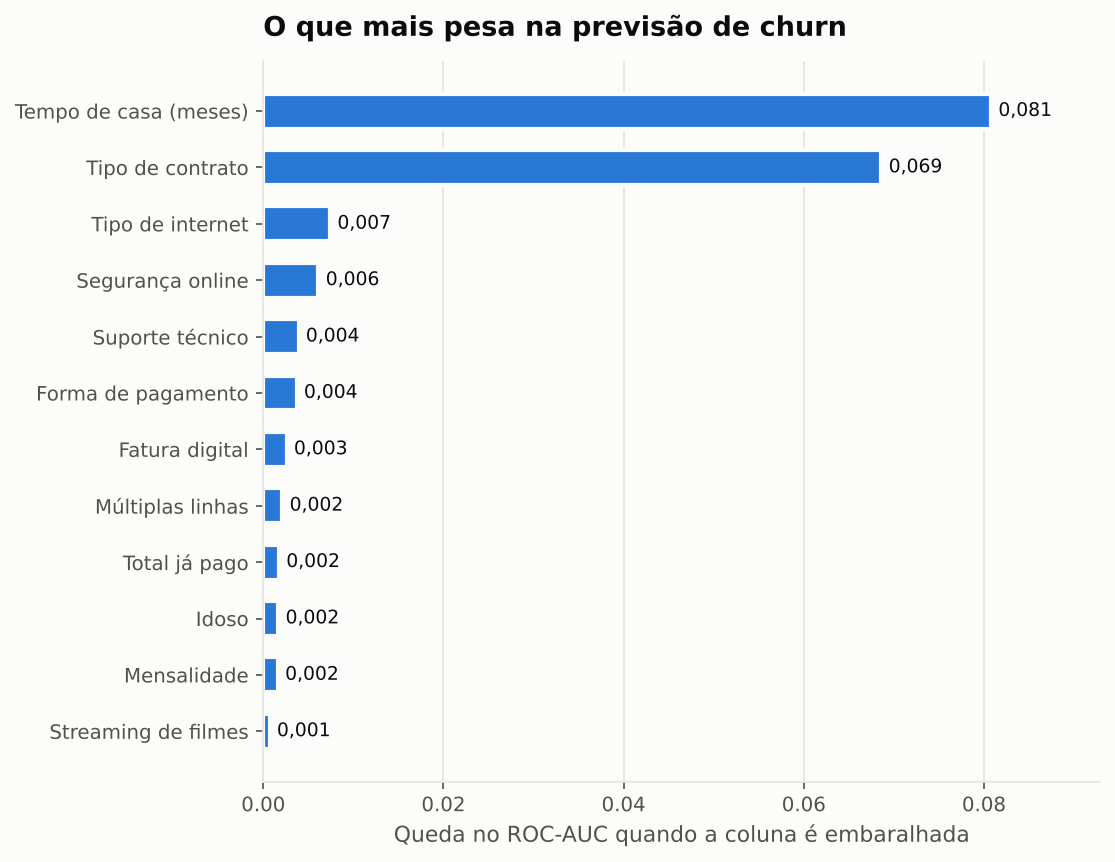

In [8]:
display(Image(FIG / "08_importancia.png"))

A importância por permutação (quanto o ROC-AUC cai quando embaralhamos cada coluna) confirma a análise exploratória: **tempo de casa** e **tipo de contrato** dominam. As demais variáveis contribuem pouco individualmente porque carregam informação parecida (ex.: quem tem contrato mensal costuma ter pouco tempo de casa).

## 5. Limitações e próximos passos
- **Dados de um único momento:** não há histórico de uso, reclamações ou atendimento, que provavelmente melhorariam muito o modelo.
- **Premissas de negócio estimadas:** custo da oferta e taxa de sucesso deveriam vir de um teste A/B real.
- **Próximos passos:** calibração de probabilidades, explicações individuais com SHAP, monitoramento de *drift* em produção e uma API (FastAPI) para servir o modelo.